# DCHSBM: overlap and runtime across ζ

Read `final_results_dchsbm_all_zetas_5_samples.npz`. Result axes are `(ζ, sampling, ε, order set)`; compute means and standard deviations along sampling.

Theoretical lines use the inference script's local-stability reference for the **current second-/third-order experiment with two-valued activities**:

\[
\Phi=\begin{pmatrix}1+\Delta^2 & 1+\zeta\Delta^2\\1+\zeta\Delta^2&1+\Delta^2\end{pmatrix},
\quad g=(\bar c_2,\bar c_3/9),\quad
\Lambda_0=\lambda_{\max}\!\left(\mathrm{diag}(\sqrt g)\Phi\mathrm{diag}(\sqrt g)\right),
\quad \varepsilon_c=\frac{\sqrt{\Lambda_0}-1}{\sqrt{\Lambda_0}+K-1}.
\]

Retain only rows and columns for the selected order set. Layer parameters come from `c_by_order`, rather than the old HSBM scalar `c`. Third order uses $\bar c_3/9$; the mean incident-hyperedge count $\nu_3=\bar c_3/2$ is not the propagation gain.
This reference assumes balanced communities, activities independent of community, and common ε and Δ across orders. It does not guarantee BP/EM convergence when learning θ.

In [1]:
from pathlib import Path
import os

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FormatStrFormatter


def compute_epsilon_c_dchsbm(orders, K, c_by_order, delta, zeta):
    """Theoretical reference for the current second-/third-order DC experiment, matching the inference script's DC branch."""
    orders = list(orders)
    if (not orders or len(set(orders)) != len(orders)
            or any(isinstance(d, (bool, np.bool_)) or d not in (2, 3) for d in orders)):
        raise ValueError("orders 必须是非空且不重复的二/三阶组合")
    if isinstance(K, (bool, np.bool_)) or not isinstance(K, (int, np.integer)) or K < 2:
        raise ValueError("K 必须是至少为 2 的整数")
    if not np.isfinite([delta, zeta]).all() or not 0 <= delta < 1 or not -1 <= zeta <= 1:
        raise ValueError("需要 0 <= delta < 1 且 -1 <= zeta <= 1")
    c_values = {int(d): float(value) for d, value in c_by_order.items()}
    gains = np.asarray([c_values[d] if d == 2 else c_values[d] / 9.0 for d in orders])
    if not np.isfinite(gains).all() or np.any(gains < 0):
        raise ValueError("分层亲和尺度必须为有限非负数")
    phi = np.array([[1 + delta**2, 1 + zeta * delta**2],
                    [1 + zeta * delta**2, 1 + delta**2]])
    indices = [int(d) - 2 for d in orders]
    root_gains = np.sqrt(gains)
    matrix = root_gains[:, None] * phi[np.ix_(indices, indices)] * root_gains[None, :]
    lambda0 = float(np.linalg.eigvalsh(matrix)[-1])
    if lambda0 < 1:
        return float("nan")  # No such local-instability boundary exists in [0, 1].
    root = np.sqrt(lambda0)
    return float((root - 1) / (root + K - 1))

## Load data and compute statistics

The original saved DCHSBM summary is included under `plot_data/dchsbm/`. The configuration below locates the extracted repository root and loads that local file. Generated empirical and analytical figures are written under `outputs/dchsbm/` by default.


In [2]:
project_dir = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "main_plot_DCHSBM.ipynb").is_file() and (parent / "plot_data").is_dir()),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Run this notebook from the repository root or a directory inside it.")
data_dir = project_dir / "plot_data" / "dchsbm"
data_file = data_dir / "final_results_dchsbm_all_zetas_5_samples.npz"
# An environment variable can override the figure directory; the default is outputs under the repository root.
fig_dir = Path(os.environ.get("DCHSBM_FIG_DIR", str(project_dir / "outputs" / "dchsbm")))
order_set_index = 0

with np.load(data_file, allow_pickle=True) as data:
    if str(data["model"].item()) != "dchsbm":
        raise ValueError("本 notebook 需要 DCHSBM 汇总数据")
    zetas = np.asarray(data["zeta_list"], dtype=float).copy()
    seed_samples = np.asarray(data["seed_sample_list"], dtype=np.int64).copy()
    eps = np.asarray(data["eps_list"], dtype=float).copy()
    order_sets = [list(map(int, sizes)) for sizes in data["selected_hye_sizes_list"]]
    overlap_all = np.asarray(data["overlap"], dtype=float).copy()
    elapsedtime_all = np.asarray(data["em_total_time"], dtype=float).copy()
    N, K = int(data["N"].item()), int(data["K"].item())
    c_by_order = {int(d): float(value) for d, value in data["c_by_order"].item().items()}
    delta = float(data["delta"].item())
    stored_theory_epsilon_c = np.asarray(data["theory_epsilon_c"], dtype=float).copy()

expected_shape = (len(zetas), len(seed_samples), len(eps), len(order_sets))
if overlap_all.shape != expected_shape or elapsedtime_all.shape != expected_shape:
    raise ValueError(f"数据轴应为 (zeta, sampling, epsilon, order_set)：{expected_shape}")
if not all(expected_shape) or len(set(seed_samples)) != len(seed_samples):
    raise ValueError("坐标轴不能为空，且 sampling 种子不能重复")
if len(set(zetas)) != len(zetas) or not np.all(np.diff(eps) > 0):
    raise ValueError("zeta 不得重复，eps 必须严格递增")
if not np.isfinite(overlap_all).all() or not np.isfinite(elapsedtime_all).all():
    raise ValueError("结果包含 NaN 或无穷值，请先检查原始推断结果")
if not 0 <= order_set_index < len(order_sets):
    raise IndexError("order_set_index 超出阶数组合范围")

num_samples = len(seed_samples)
overlap_mean = overlap_all.mean(axis=1)              # (zeta, epsilon, order_set)
overlap_std = overlap_all.std(axis=1, ddof=0)
elapsedtime_mean = elapsedtime_all.mean(axis=1) / 60  # Minutes
elapsedtime_std = elapsedtime_all.std(axis=1, ddof=0) / 60

theory_epsilon_c = np.asarray([
    [compute_epsilon_c_dchsbm(orders, K, c_by_order, delta, float(zeta))
     for orders in order_sets]
    for zeta in zetas
])
if (theory_epsilon_c.shape != stored_theory_epsilon_c.shape
        or not np.allclose(theory_epsilon_c, stored_theory_epsilon_c,
                           rtol=1e-12, atol=1e-14, equal_nan=True)):
    raise ValueError("重算的 DC 理论阈值与 NPZ 记录不一致，请核对实验参数和理论版本")

fig_dir.mkdir(parents=True, exist_ok=True)
print(f"数据形状: {overlap_all.shape}; {num_samples} 次 sampling")
print(f"N={N}, K={K}, c_by_order={c_by_order}, delta={delta}")
print("实际采样种子:", seed_samples.tolist())
for zi, zeta in enumerate(zetas):
    for oi, orders in enumerate(order_sets):
        print(f"zeta={zeta:g}, orders={orders}: epsilon_c={theory_epsilon_c[zi, oi]:.12f}")
print("图片输出目录:", fig_dir)

数据形状: (3, 5, 40, 1); 5 次 sampling
N=30000, K=4, c_by_order={2: 4.0, 3: 12.0}, delta=0.8
实际采样种子: [33158374, 115579757, 1273345680, 1465339467, 1952249162]
zeta=-1, orders=[2, 3]: epsilon_c=0.284550525411
zeta=0, orders=[2, 3]: epsilon_c=0.304154531889
zeta=1, orders=[2, 3]: epsilon_c=0.328574763829
图片输出目录: d:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\dchsbm


## Overlap

Each curve represents one ζ: solid lines show the mean of five samples, with ±1 standard deviation shading. The same-color dashed line is its DC theoretical reference threshold. The displayed range follows the actual ε grid.

已保存: d:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\dchsbm\overlap_dchsbm_zeta.png


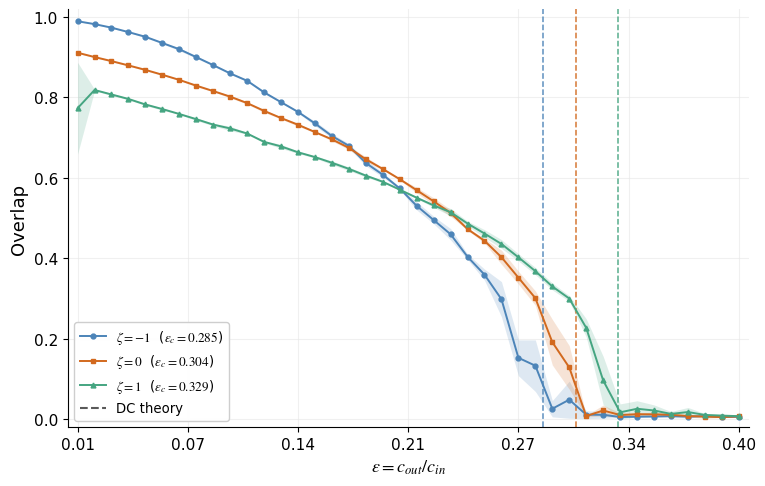

In [3]:
style = {
    "font.family": "DejaVu Sans", "mathtext.fontset": "stix", "text.usetex": False,
    "font.size": 11, "axes.labelsize": 13, "xtick.labelsize": 11, "ytick.labelsize": 11,
    "figure.facecolor": "white", "axes.facecolor": "white",
}
colors = ["#4C84B8", "#D2691E", "#45A581"]
markers = ["o", "s", "^"]


def plot_by_zeta(mean, std, ylabel, filename, overlap_scale=False):
    orders = order_sets[order_set_index]
    with plt.rc_context(style):
        fig, ax = plt.subplots(figsize=(7.8, 5.0))
        handles = []
        for zi, zeta in enumerate(zetas):
            color = colors[zi % len(colors)]
            y, spread = mean[zi, :, order_set_index], std[zi, :, order_set_index]
            lower, upper = np.maximum(y - spread, 0), y + spread
            if overlap_scale:
                upper = np.minimum(upper, 1)
            threshold = theory_epsilon_c[zi, order_set_index]
            label = fr"$\zeta={zeta:g}$"
            if np.isfinite(threshold):
                label += fr"  ($\varepsilon_c={threshold:.3f}$)"
            ax.fill_between(eps, lower, upper, color=color, alpha=0.18, linewidth=0)
            line, = ax.plot(eps, y, color=color, marker=markers[zi % len(markers)],
                            markersize=3.5, linewidth=1.4, label=label, zorder=3)
            handles.append(line)
            if np.isfinite(threshold):
                ax.axvline(threshold, color=color, linestyle="--", linewidth=1.1, alpha=0.9)

        if np.isfinite(theory_epsilon_c[:, order_set_index]).any():
            handles.append(Line2D([0], [0], color="0.35", linestyle="--", label="DC theory"))
        ax.legend(handles=handles, loc="best", fontsize=9.5,
                  facecolor="white", edgecolor="0.80", framealpha=0.95)
        ax.set_xlabel(r"$\varepsilon=c_{out}/c_{in}$")
        ax.set_ylabel(ylabel)
        order_label = ", ".join(map(str, orders))
        # ax.set_title(fr"DCHSBM: orders $\{{{order_label}\}}$, {num_samples} samples", fontsize=12)
        margin = max(float(np.ptp(eps)) * 0.015, 0.001)
        ax.set_xlim(float(eps.min()) - margin, float(eps.max()) + margin)
        ax.set_xticks(np.linspace(eps.min(), eps.max(), 7))
        ax.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
        if overlap_scale:
            ax.set_ylim(-0.02, 1.02)
            ax.set_yticks(np.arange(0, 1.01, 0.2))
            ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
        else:
            ax.set_ylim(bottom=0)
        ax.tick_params(direction="out", top=False, right=False)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.set_axisbelow(True)
        ax.grid(color="0.90", linewidth=0.8, alpha=0.6)
        fig.tight_layout()
        save_path = fig_dir / filename
        fig.savefig(save_path, dpi=300, bbox_inches="tight", facecolor="white")
        print("已保存:", save_path)
        plt.show()
        return fig, ax


fig_overlap, ax_overlap = plot_by_zeta(
    overlap_mean, overlap_std, "Overlap", "overlap_dchsbm_zeta.png", overlap_scale=True
)

## Runtime (minutes)

Compute the sampling mean and standard deviation of `em_total_time`, then convert seconds to minutes. This records elapsed runtime; the current experiment uses `em_iter=1`, so it does not measure time to convergence.

已保存: d:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\dchsbm\time_dchsbm_zeta.png


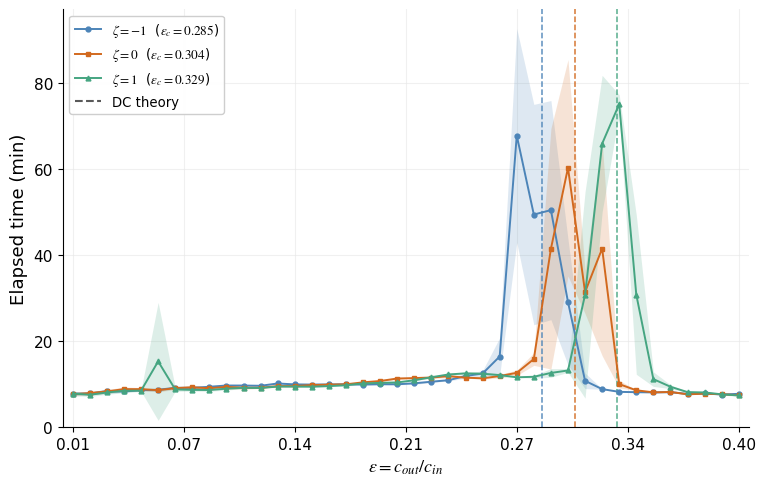

In [4]:
fig_time, ax_time = plot_by_zeta(
    elapsedtime_mean, elapsedtime_std, "Elapsed time (min)", "time_dchsbm_zeta.png"
)

## Analytical figures and table: second and third orders

This section runs independently of the experiment NPZ files. Compute the paper's table and three standalone analytical figures: local-instability boundaries, order allocation at fixed total mean degree, and the isolated-node fraction.

- Table and correlation plot: $K=4$, $\nu_2=\nu_3=2$; the table uses $\Delta_2=\Delta_3=0.5$, and the plot compares $\Delta=0.2,0.5,0.8$.
- Fixed-budget plot: $\bar k_{\mathrm h}=6$, $\Delta_2=\Delta_3=0.5$, $\nu_2=6(1-f_3)$, $\nu_3=6f_3$.
- Isolated-node plot: $\nu_2=\nu_3=2$, comparing $\Delta=0.2,0.5,0.8$.

Here $\nu_d$ is mean incidence degree and the affinity scale is $\bar c_d=(d-1)\nu_d$. These parameters differ from the finite-graph experiment above.

Export PNG/PDF figures and CSV/LaTeX tables. The default destination is the figure directory's `analytical` subdirectory; override it with `DCHSBM_ANALYTIC_FIG_DIR`.

In [5]:
from pathlib import Path
import os
import csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

analytic_project_dir = project_dir
analytic_base_dir = Path(os.environ.get(
    "DCHSBM_FIG_DIR",
    str(analytic_project_dir / "outputs" / "dchsbm"),
))
analytic_fig_dir = Path(os.environ.get(
    "DCHSBM_ANALYTIC_FIG_DIR", str(analytic_base_dir / "analytical")
))
analytic_fig_dir.mkdir(parents=True, exist_ok=True)

analytic_K = 4
analytic_nu2 = analytic_nu3 = 2.0
analytic_table_delta = 0.5
analytic_delta_values = (0.2, 0.5, 0.8)
analytic_total_degree = 6.0
analytic_allocation_delta = 0.5
analytic_zeta_values = (-1.0, 0.0, 1.0)
analytic_zeta_grid = np.linspace(-1.0, 1.0, 401)
analytic_f3_grid = np.linspace(0.0, 1.0, 401)
analytic_colors = ("#4C84B8", "#D2691E", "#45A581")
analytic_linestyles = ("-", "--", "-.")
analytic_style = {
    "font.family": "DejaVu Sans", "mathtext.fontset": "stix", "text.usetex": False,
    "font.size": 11, "axes.labelsize": 13, "xtick.labelsize": 11, "ytick.labelsize": 11,
    "figure.facecolor": "white", "axes.facecolor": "white",
}


def _analytical_inputs(nu2, nu3, delta2, delta3, zeta):
    values = np.broadcast_arrays(*[
        np.asarray(x, dtype=float) for x in (nu2, nu3, delta2, delta3, zeta)
    ])
    if not all(np.isfinite(x).all() for x in values):
        raise ValueError("Analytical parameters must be finite")
    nu2, nu3, delta2, delta3, zeta = values
    if np.any(nu2 < 0) or np.any(nu3 < 0):
        raise ValueError("Mean degrees must be nonnegative")
    if np.any((delta2 < 0) | (delta2 >= 1)) or np.any((delta3 < 0) | (delta3 >= 1)):
        raise ValueError("Require 0 <= delta2, delta3 < 1")
    if np.any((zeta < -1) | (zeta > 1)):
        raise ValueError("Require -1 <= zeta <= 1")
    return nu2, nu3, delta2, delta3, zeta


def analytical_two_order_rho(nu2, nu3, delta2, delta3, zeta, lambda2=1.0, lambda3=1.0):
    """Spectral radius of the second-/third-order transmission matrix; equals rho(M0) when lambda2=lambda3=1."""
    nu2, nu3, delta2, delta3, zeta = _analytical_inputs(nu2, nu3, delta2, delta3, zeta)
    lambda2, lambda3 = np.asarray(lambda2, dtype=float), np.asarray(lambda3, dtype=float)
    if (not np.isfinite(lambda2).all() or not np.isfinite(lambda3).all()
            or np.any((lambda2 < 0) | (lambda2 > 1))
            or np.any((lambda3 < 0) | (lambda3 > 1))):
        raise ValueError("Require 0 <= lambda2, lambda3 <= 1")
    phi22, phi33 = 1.0 + delta2**2, 1.0 + delta3**2
    phi23 = 1.0 + zeta * delta2 * delta3
    m22 = nu2 * lambda2**2 * phi22
    m23 = (2.0 / 9.0) * nu3 * lambda3**2 * phi23
    m32 = nu2 * lambda2**2 * phi23
    m33 = (2.0 / 9.0) * nu3 * lambda3**2 * phi33
    return 0.5 * (m22 + m33 + np.sqrt((m22 - m33)**2 + 4.0 * m23 * m32))


def analytical_epsilon_c(nu2, nu3, delta2, delta3, zeta, K=4):
    """Local-instability boundary for a common signal; return NaN for rho(M0)<1 and zero at rho(M0)=1."""
    if isinstance(K, (bool, np.bool_)) or not isinstance(K, (int, np.integer)) or K < 2:
        raise ValueError("K must be an integer >= 2")
    rho0 = analytical_two_order_rho(nu2, nu3, delta2, delta3, zeta)
    root = np.sqrt(rho0)
    return np.where(rho0 >= 1.0, (root - 1.0) / (root + K - 1.0), np.nan)


def analytical_isolated_fraction(nu2, nu3, delta2, delta3, zeta):
    """P0 = sum_{x,y} (1+zeta*x*y)/4 * exp[-nu2(1+delta2*x)-nu3(1+delta3*y)]。"""
    nu2, nu3, delta2, delta3, zeta = _analytical_inputs(nu2, nu3, delta2, delta3, zeta)
    p0 = np.zeros_like(zeta, dtype=float)
    # This four-term sum equals the paper's cosh/sinh expression and avoids cosh overflow at large mean degree.
    for x in (-1.0, 1.0):
        for y in (-1.0, 1.0):
            probability = (1.0 + zeta * x * y) / 4.0
            p0 += probability * np.exp(-nu2 * (1.0 + delta2*x) - nu3 * (1.0 + delta3*y))
    return p0


def save_analytical_figure(fig, stem):
    fig.tight_layout()
    for suffix in ("png", "pdf"):
        filename = analytic_fig_dir / f"{stem}.{suffix}"
        fig.savefig(filename, dpi=300, bbox_inches="tight", facecolor="white")
        print("已保存:", filename)
    plt.show()


def format_analytical_axes(ax, xlabel, ylabel):
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.tick_params(direction="out", top=False, right=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(color="0.90", linewidth=0.8, alpha=0.6)


def save_analytical_table(stem, headers, latex_headers, rows):
    with (analytic_fig_dir / f"{stem}.csv").open("w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(headers)
        writer.writerows(rows)
    formatted_rows = [[f"{row[0]:g}", *[f"{value:.6f}" for value in row[1:]]] for row in rows]
    lines = [r"\begin{tabular}{" + "r" * len(headers) + "}",
             " & ".join(latex_headers) + r" \\", r"\hline"]
    lines += [" & ".join(row) + r" \\" for row in formatted_rows]
    lines.append(r"\end{tabular}")
    (analytic_fig_dir / f"{stem}.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")
    markdown = ["| " + " | ".join(latex_headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
    markdown += ["| " + " | ".join(row) + " |" for row in formatted_rows]
    display(Markdown("\n".join(markdown)))
    print("表格输出目录:", analytic_fig_dir)

print("理论图表输出目录:", analytic_fig_dir)

理论图表输出目录: d:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\dchsbm\analytical


### Analytical table: varying only cross-order correlation

With $K=4$, $\nu_2=\nu_3=2$, and $\Delta_2=\Delta_3=0.5$, compute $\Phi_{23}$, $\rho(\mathbf M_0)$, and $\varepsilon_c$ for the paper's analytical two-order benchmark.

In [6]:
analytic_benchmark_rows = []
for analytic_zeta in analytic_zeta_values:
    analytic_benchmark_rows.append([
        analytic_zeta,
        1.0 + analytic_zeta * analytic_table_delta**2,
        float(analytical_two_order_rho(
            analytic_nu2, analytic_nu3, analytic_table_delta, analytic_table_delta, analytic_zeta)),
        float(analytical_epsilon_c(
            analytic_nu2, analytic_nu3, analytic_table_delta, analytic_table_delta, analytic_zeta, K=analytic_K)),
    ])
save_analytical_table(
    "DCHSBM_analytical_benchmark",
    ["zeta", "Phi23", "rho_M0", "epsilon_c"],
    [r"$\zeta$", r"$\Phi_{23}$", r"$\rho(\mathbf M_0)$", r"$\varepsilon_c$"],
    analytic_benchmark_rows,
)

| $\zeta$ | $\Phi_{23}$ | $\rho(\mathbf M_0)$ | $\varepsilon_c$ |
| --- | --- | --- | --- |
| -1 | 0.750000 | 2.729949 | 0.140202 |
| 0 | 1.000000 | 2.882069 | 0.148513 |
| 1 | 1.250000 | 3.055556 | 0.157543 |

表格输出目录: d:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\dchsbm\analytical


### Critical value versus cross-order correlation

Fix $\nu_2=\nu_3=2$ and compare $\Delta_2=\Delta_3=\Delta=0.2,0.5,0.8$. Each curve varies only $\zeta$, preserving single-order marginal distributions and mean degrees.

已保存: d:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\dchsbm\analytical\DCHSBM_analytical_correlation.png
已保存: d:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\dchsbm\analytical\DCHSBM_analytical_correlation.pdf


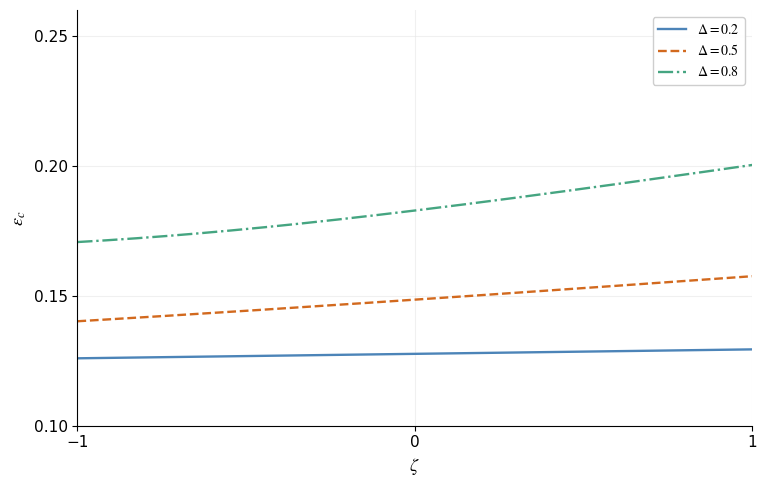

In [7]:
with plt.rc_context(analytic_style):
    fig_analytic_correlation, ax_analytic_correlation = plt.subplots(figsize=(7.8, 5.0))
    for analytic_delta, analytic_color, analytic_line in zip(
        analytic_delta_values, analytic_colors, analytic_linestyles
    ):
        analytic_boundary_curve = analytical_epsilon_c(
            analytic_nu2, analytic_nu3, analytic_delta, analytic_delta,
            analytic_zeta_grid, K=analytic_K,
        )
        ax_analytic_correlation.plot(
            analytic_zeta_grid, analytic_boundary_curve, color=analytic_color,
            linestyle=analytic_line, linewidth=1.7, label=fr"$\Delta={analytic_delta:g}$",
        )
    format_analytical_axes(ax_analytic_correlation, r"$\zeta$", r"$\varepsilon_c$")
    # ax_analytic_correlation.set_title("Local instability", loc="left", fontsize=12)
    ax_analytic_correlation.set_xlim(-1, 1)
    ax_analytic_correlation.set_ylim(0.10, 0.26)
    ax_analytic_correlation.set_xticks([-1, 0, 1])
    ax_analytic_correlation.set_yticks([0.10, 0.15, 0.20, 0.25])
    ax_analytic_correlation.legend(loc="best", fontsize=10, framealpha=0.95)
    save_analytical_figure(fig_analytic_correlation, "DCHSBM_analytical_correlation")

### Order allocation at fixed total mean degree

With $\bar k_{\mathrm h}=6$ and $\Delta_2=\Delta_3=0.5$, compare $\zeta=-1,0,1$. The horizontal axis $f_3$ is the third-order incidence fraction: $\nu_2=6(1-f_3)$, $\nu_3=6f_3$. Endpoints are purely second or third order, where the three curves coincide.

已保存: d:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\dchsbm\analytical\DCHSBM_analytical_allocation.png
已保存: d:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\dchsbm\analytical\DCHSBM_analytical_allocation.pdf


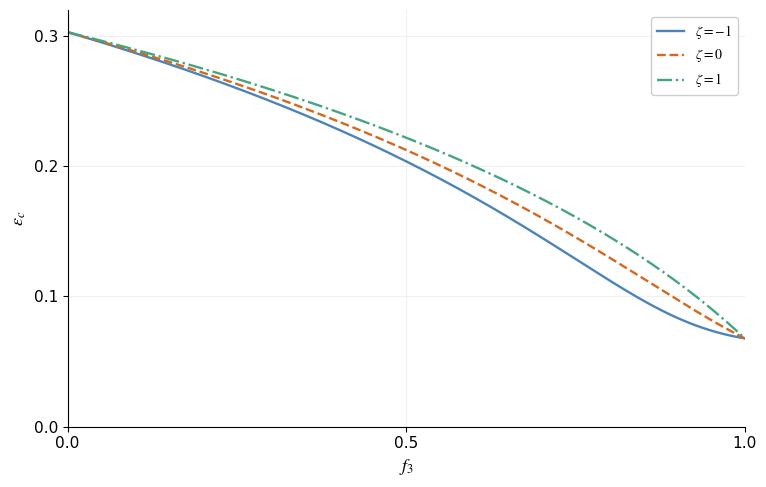

In [8]:
analytic_allocation_nu2 = analytic_total_degree * (1.0 - analytic_f3_grid)
analytic_allocation_nu3 = analytic_total_degree * analytic_f3_grid
with plt.rc_context(analytic_style):
    fig_analytic_allocation, ax_analytic_allocation = plt.subplots(figsize=(7.8, 5.0))
    for analytic_zeta, analytic_color, analytic_line in zip(
        analytic_zeta_values, analytic_colors, analytic_linestyles
    ):
        analytic_allocation_curve = analytical_epsilon_c(
            analytic_allocation_nu2, analytic_allocation_nu3,
            analytic_allocation_delta, analytic_allocation_delta,
            analytic_zeta, K=analytic_K,
        )
        ax_analytic_allocation.plot(
            analytic_f3_grid, analytic_allocation_curve, color=analytic_color,
            linestyle=analytic_line, linewidth=1.7, label=fr"$\zeta={analytic_zeta:g}$",
        )
    format_analytical_axes(ax_analytic_allocation, r"$f_3$", r"$\varepsilon_c$")
    # ax_analytic_allocation.set_title("Fixed total mean degree", loc="left", fontsize=12)
    ax_analytic_allocation.set_xlim(0, 1)
    ax_analytic_allocation.set_ylim(0, 0.32)
    ax_analytic_allocation.set_xticks([0, 0.5, 1])
    ax_analytic_allocation.set_yticks([0, 0.1, 0.2, 0.3])
    ax_analytic_allocation.legend(loc="best", fontsize=10, framealpha=0.95)
    save_analytical_figure(fig_analytic_allocation, "DCHSBM_analytical_allocation")

### Isolated-node fraction

Use $\nu_2=\nu_3=2$ and $\Delta_2=\Delta_3=\Delta$. Isolated nodes have no observed incidences in either order, with fraction

$$P_0=e^{-(\nu_2+\nu_3)}\left[\cosh(\nu_2\Delta_2)\cosh(\nu_3\Delta_3)+\zeta\sinh(\nu_2\Delta_2)\sinh(\nu_3\Delta_3)\right].$$

Compare $\Delta=0.2,0.5,0.8$ below and list the three values at $\Delta=0.5$.

已保存: d:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\dchsbm\analytical\DCHSBM_analytical_isolated_nodes.png
已保存: d:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\dchsbm\analytical\DCHSBM_analytical_isolated_nodes.pdf


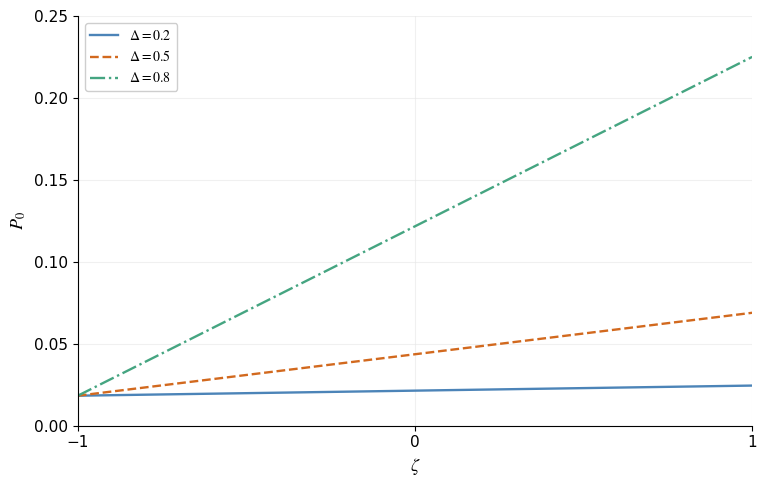

| $\zeta$ | $P_0$ |
| --- | --- |
| -1 | 0.018316 |
| 0 | 0.043611 |
| 1 | 0.068907 |

表格输出目录: d:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\dchsbm\analytical


In [9]:
with plt.rc_context(analytic_style):
    fig_analytic_isolation, ax_analytic_isolation = plt.subplots(figsize=(7.8, 5.0))
    for analytic_delta, analytic_color, analytic_line in zip(
        analytic_delta_values, analytic_colors, analytic_linestyles
    ):
        analytic_isolation_curve = analytical_isolated_fraction(
            analytic_nu2, analytic_nu3, analytic_delta, analytic_delta, analytic_zeta_grid,
        )
        ax_analytic_isolation.plot(
            analytic_zeta_grid, analytic_isolation_curve, color=analytic_color,
            linestyle=analytic_line, linewidth=1.7, label=fr"$\Delta={analytic_delta:g}$",
        )
    format_analytical_axes(ax_analytic_isolation, r"$\zeta$", r"$P_0$")
    # ax_analytic_isolation.set_title("Isolated nodes", loc="left", fontsize=12)
    ax_analytic_isolation.set_xlim(-1, 1)
    ax_analytic_isolation.set_ylim(0, 0.25)
    ax_analytic_isolation.set_xticks([-1, 0, 1])
    ax_analytic_isolation.set_yticks(np.arange(0, 0.251, 0.05))
    ax_analytic_isolation.legend(loc="best", fontsize=10, framealpha=0.95)
    save_analytical_figure(fig_analytic_isolation, "DCHSBM_analytical_isolated_nodes")

analytic_isolation_rows = [[
    analytic_zeta,
    float(analytical_isolated_fraction(
        analytic_nu2, analytic_nu3, analytic_table_delta, analytic_table_delta, analytic_zeta)),
] for analytic_zeta in analytic_zeta_values]
save_analytical_table(
    "DCHSBM_analytical_isolated_benchmark", ["zeta", "P0"],
    [r"$\zeta$", r"$P_0$"], analytic_isolation_rows,
)